# AI SCI 290A Project 1: Weather Prediction
Using ERA5 data to answer the question Can we predict the weather at UC Irvine?

# 1. Imports

In [81]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
import seaborn as sns
import glob
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neural_network import MLPRegressor, MLPClassifier
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler

# 2. Preliminary Exploration

In [82]:
DATA_DIR = "./data/"

In [83]:
temp_files = sorted(
    glob.glob(f"{DATA_DIR}/**/*.nc", recursive=True)
)
ds = xr.open_mfdataset(
    temp_files,
    combine="by_coords"
)

## Avg temp

Text(0.5, 1.0, 'Mean 2m temp')

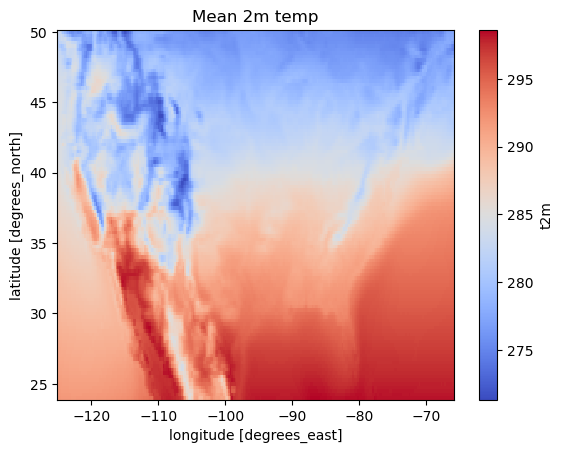

In [84]:
fig, ax = plt.subplots()
ds.t2m.mean(dim="valid_time").plot(cmap="coolwarm")
ax.set_title("Mean 2m temp")

## Temperature over time at UC Irvine

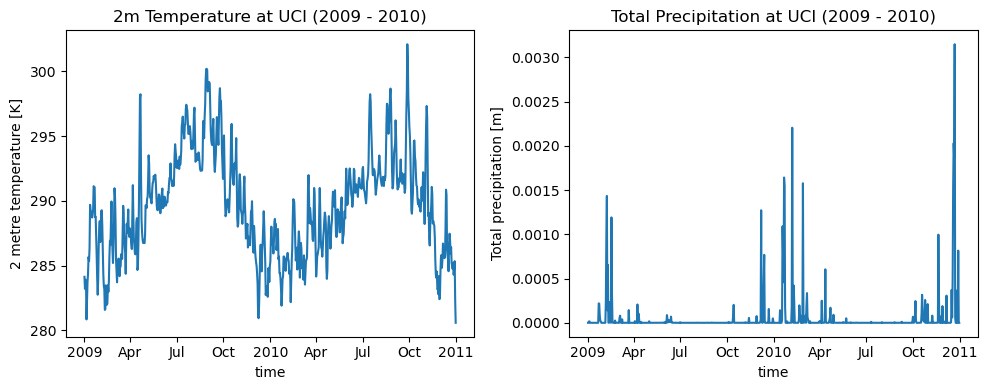

In [85]:
lat_uci, lon_uci = 33.64, -117.84

ds_uci = ds.sel(latitude=lat_uci, longitude=lon_uci, method="nearest")

fig, axs = plt.subplots(
    ncols=2,
    figsize=(10, 4)
)
ds_uci.t2m.plot(ax=axs[0])
axs[0].set_title("2m Temperature at UCI (2009 - 2010)")

ds_uci.tp.plot(ax=axs[1])
axs[1].set_title("Total Precipitation at UCI (2009 - 2010)")

fig.tight_layout()

## Feature Engineering

In [86]:
ds_uci["t2m"] = ds_uci["t2m"]-273.15

In [87]:
# Calcs and adds 3 and 7 day rolling average and previous day columns
ds_uci['rolling_3'] = ds_uci['t2m'].rolling(valid_time=3).mean()  # up to yesterday
ds_uci['rolling_7'] = ds_uci['t2m'].rolling(valid_time=7).mean()
ds_uci["target_t2m"] = ds_uci["t2m"].shift(valid_time=-1)

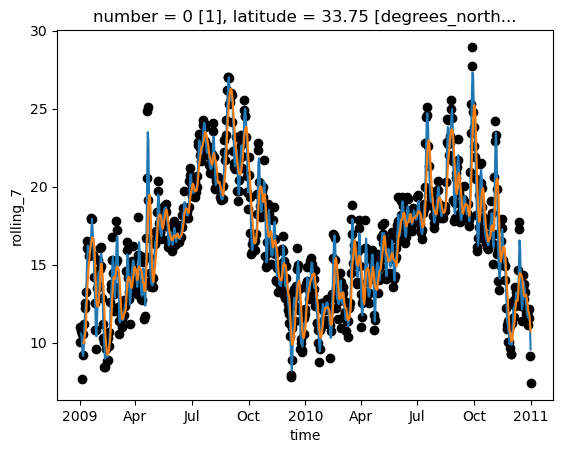

In [88]:
fig, ax = plt.subplots()

ds_uci["t2m"].plot.scatter("valid_time", color="black")
ds_uci["rolling_3"].plot()
ds_uci["rolling_7"].plot()

# 3. Temperature

In [89]:
# Prep for regression by deleting nan rows
ds_uci = ds_uci.dropna(dim="valid_time")
n_samples = len(ds_uci["valid_time"])

# Test train split
X = ds_uci.to_dataframe()[["t2m", "rolling_3", "rolling_7"]]
y = ds_uci["target_t2m"].values

X_train, X_split, y_train, y_split = train_test_split(X, y, random_state=210, shuffle=False, test_size=0.5)

X_val, X_test, y_val, y_test = train_test_split(X_split, y_split, random_state=210, shuffle=False, test_size=0.5)


In [90]:
# Data rescaling

X_scaler = StandardScaler().fit(X_train)

X_train_sc = X_scaler.transform(X_train)
X_val_sc = X_scaler.transform(X_val)
X_test_sc = X_scaler.transform(X_test)

y_scaler = StandardScaler()
y_train_clean = y_train.reshape(-1, 1)

y_scaler.fit(y_train_clean)
y_train_sc = y_scaler.transform(y_train_clean)
y_val_sc = y_scaler.transform(y_val.reshape(-1, 1))
y_test_sc = y_scaler.transform(y_test.reshape(-1, 1))

In [91]:
# Set up metrics
train_mse = pd.DataFrame(columns=["model", "score", "mse"])
val_mse = pd.DataFrame(columns=["model", "score", "mse"])

## Linear Regression
Predicts using a 3-day rolling average, 7-day rolling average, and the previous day's temperature.

### Predictors: Previous Day, 3-Day Rolling, and 7-Day Rolling

In [92]:
reg = LinearRegression()
reg.fit(X_train, y_train)

y_pred = reg.predict(X_train)

train_mse.loc[len(train_mse)] = {
    'model': 'linear_reg_3', 
    'score': reg.score(X_train, y_train), 
    'mse': mean_squared_error(y_train, y_pred)
    }

y_pred = reg.predict(X_val)

val_mse.loc[len(val_mse)] = {
    'model': 'linear_reg_3', 
    'score': reg.score(X_val, y_val), 
    'mse': mean_squared_error(y_val, y_pred)
    }

## Neural Network - 3 var

In [93]:
reg = MLPRegressor(
    random_state=222,
    )
reg.fit(X_train_sc, y_train_sc.ravel())

y_pred = reg.predict(X_train_sc)

train_mse.loc[len(train_mse)] = {
    'model': 'nn_3', 
    'score': reg.score(X_train_sc, y_train_sc), 
    'mse': mean_squared_error(y_train_sc, y_pred)
    }

y_pred = reg.predict(X_val_sc)

y_pred = y_scaler.inverse_transform(y_pred.reshape(-1, 1))

val_mse.loc[len(val_mse)] = {
    'model': 'nn_3', 
    'score': reg.score(X_val_sc, y_val_sc), 
    'mse': mean_squared_error(y_val, y_pred)
    }

In [94]:
import copy

import torch
import torch.nn as nn
from sklearn.metrics import r2_score
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(222)

class TemperatureLSTM(nn.Module):
    def __init__(self, input_dim=3, hidden_dim=32, num_layers=1, output_dim=1):
        super().__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])

def to_sequence(features, labels):
    # One day per sample, three features. Shape (samples, 1, 3).
    x = torch.from_numpy(np.asarray(features, dtype=np.float32)).unsqueeze(1)
    y_tensor = torch.from_numpy(np.asarray(labels, dtype=np.float32))
    return x, y_tensor

MAX_EPOCHS = 300
BATCH_SIZE = 32
PATIENCE = 25
FULL = 1.0  # per-epoch learning-rate multiplier; 1 keeps the full learning rate
CRITERION = nn.MSELoss()

def train_model(
    model,
    X_train,
    y_train,
    X_val,
    y_val, 
    criterion=CRITERION,
    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    lr=1e-3,
    patience=PATIENCE,
    lr_decay=FULL,
):
    """Train a regression network and restore the weights with the best validation loss."""

    def as_batch(features, labels):
        x = torch.as_tensor(np.asarray(features), dtype=torch.float32)
        y = torch.as_tensor(np.asarray(labels), dtype=torch.float32)
        if x.ndim == 2:
            x = x.unsqueeze(1)  # (samples, 1, features) for the LSTM
        if y.ndim == 1:
            y = y.unsqueeze(-1)
        return x, y

    X_tr, y_tr = as_batch(X_train, y_train)
    X_va, y_va = as_batch(X_val, y_val)
    loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=batch_size, shuffle=True)

    criterion = criterion
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=lr_decay)

    best_state = copy.deepcopy(model.state_dict())
    best_val = float("inf")
    wait = 0
    stopped = epochs

    for epoch in range(1, epochs + 1):
        model.train()
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

        model.eval()
        with torch.no_grad():
            val_loss = criterion(model(X_va), y_va).item()
        if val_loss < best_val:
            best_val = val_loss
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                stopped = epoch
                break
        scheduler.step()

    model.load_state_dict(best_state)
    model.eval()
    return model, stopped

In [95]:
model, epoch = train_model(
    TemperatureLSTM(),
    X_train_sc,
    y_train_sc,
    X_val_sc,
    y_val_sc,
)

# Measures the train metrics
X_train_seq, _ = to_sequence(X_train_sc, y_train_sc)
with torch.no_grad():
    pred_sc = model(X_train_seq).numpy()

pred_c = y_scaler.inverse_transform(pred_sc)
lstm_r2 = r2_score(y_train, pred_c)
lstm_mse = mean_squared_error(y_train, pred_c)

train_mse.loc[len(train_mse)] = {
    "model": "lstm_3",
    "score": lstm_r2,
    "mse": lstm_mse,
}

# Measures the test metrics
X_val_seq, _ = to_sequence(X_val_sc, y_val_sc)
with torch.no_grad():
    pred_sc = model(X_val_seq).numpy()

pred_c = y_scaler.inverse_transform(pred_sc)
lstm_r2 = r2_score(y_val, pred_c)
lstm_mse = mean_squared_error(y_val, pred_c)

val_mse.loc[len(val_mse)] = {
    "model": "lstm_3",
    "score": lstm_r2,
    "mse": lstm_mse,
}

print(f"stopped after epoch {epoch}")
print(f"LSTM test  R² {lstm_r2:.3f}   MSE {lstm_mse:.3f}")

stopped after epoch 179
LSTM test  R² 0.821   MSE 1.131


## Neural Network - all var

In [96]:
X = ds_uci.to_dataframe()[["t2m", "rolling_3", "rolling_7", "v10", "u10", "msl", "tp"]]
y = ds_uci["target_t2m"].values

X_train, X_split, y_train, y_split = train_test_split(X, y, random_state=210, shuffle=False, test_size=0.5)
X_val, X_test, y_val, y_test = train_test_split(X_split, y_split, random_state=210, shuffle=False, test_size=0.5)

# Data rescaling

X_scaler = StandardScaler().fit(X_train)

X_train_sc = X_scaler.transform(X_train)
X_val_sc = X_scaler.transform(X_val)
X_test_sc = X_scaler.transform(X_test)

y_scaler = StandardScaler()
y_train_clean = y_train.reshape(-1, 1)

y_scaler.fit(y_train_clean)
y_train_sc = y_scaler.transform(y_train_clean)
y_val_sc = y_scaler.transform(y_val.reshape(-1, 1))
y_test_sc = y_scaler.transform(y_test.reshape(-1, 1))

In [97]:
reg = MLPRegressor(
    random_state=222,
    )
reg.fit(X_train_sc, y_train_sc.ravel())

# Train
y_pred = reg.predict(X_train_sc)

y_pred = y_scaler.inverse_transform(y_pred.reshape(-1, 1))

train_mse.loc[len(train_mse)] = {
    'model': 'nn_a', 
    'score': reg.score(X_train_sc, y_train_sc), 
    'mse': mean_squared_error(y_train, y_pred)
    }

# Validation
y_pred = reg.predict(X_val_sc)

y_pred = y_scaler.inverse_transform(y_pred.reshape(-1, 1))

val_mse.loc[len(val_mse)] = {
    'model': 'nn_a', 
    'score': reg.score(X_val_sc, y_val_sc), 
    'mse': mean_squared_error(y_val, y_pred)
    }

In [98]:
model, epoch = train_model(
    TemperatureLSTM(input_dim=7),
    X_train_sc,
    y_train_sc,
    X_val_sc,
    y_val_sc,
)

# Measures the train metrics
X_train_seq, _ = to_sequence(X_train_sc, y_train_sc)
with torch.no_grad():
    pred_sc = model(X_train_seq).numpy()

pred_c = y_scaler.inverse_transform(pred_sc)
lstm_r2 = r2_score(y_train, pred_c)
lstm_mse = mean_squared_error(y_train, pred_c)

train_mse.loc[len(train_mse)] = {
    "model": "lstm_a",
    "score": lstm_r2,
    "mse": lstm_mse,
}

# Measures the test metrics
X_val_seq, _ = to_sequence(X_val_sc, y_val_sc)
with torch.no_grad():
    pred_sc = model(X_val_seq).numpy()

pred_c = y_scaler.inverse_transform(pred_sc)
lstm_r2 = r2_score(y_val, pred_c)
lstm_mse = mean_squared_error(y_val, pred_c)

val_mse = val_mse[val_mse["model"] != "lstm"]

val_mse.loc[len(val_mse)] = {
    "model": "lstm_a",
    "score": lstm_r2,
    "mse": lstm_mse,
}

print(f"stopped after epoch {epoch}")
print(f"LSTM  R² {lstm_r2:.3f}   MSE {lstm_mse:.3f}")

stopped after epoch 165
LSTM  R² 0.835   MSE 1.045


## Neural Network - Spatial Data

In [99]:
t_yest = ds["t2m"].shift(valid_time=1)

lat_uci, lon_uci = 33.64, -117.84
half = 2.0  # degrees; 0.25° grid → 17×17 points

window = t_yest.sel(
    latitude=slice(lat_uci + half, lat_uci - half),   # north → south
    longitude=slice(lon_uci - half, lon_uci + half),
)
X_window = (
    window.stack(space=("latitude", "longitude"))
    .transpose("valid_time", "space")
    .values
)  # shape (time, 289)

## Metrics and Comparison

In [100]:
val_mse

,model,score,mse
0,linear_reg_3,0.817414,1.154963
1,nn_3,0.813562,1.179329
2,lstm_3,0.821133,1.131439
3,nn_a,0.796601,1.286616
4,lstm_a,0.834856,1.044633


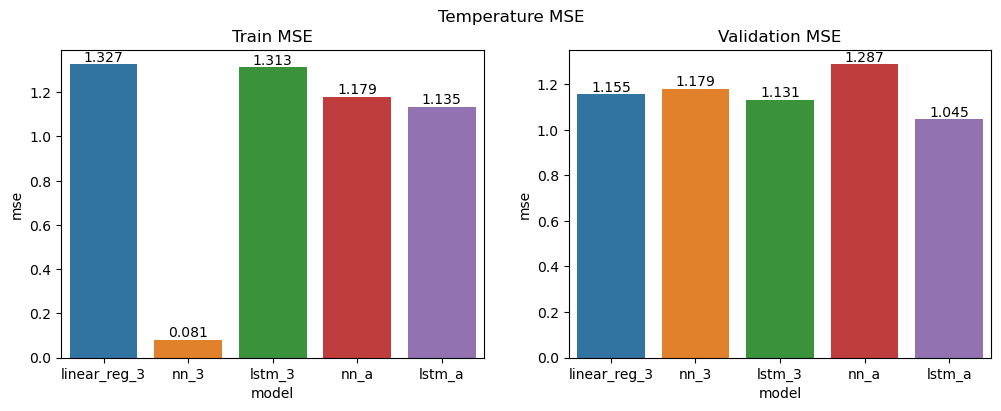

In [101]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

fig.suptitle("Temperature MSE")
ax[0].set_title("Train MSE")
ax[1].set_title("Validation MSE")
sns.barplot(data=train_mse, x="model", y="mse", hue="model", ax=ax[0])
sns.barplot(data=val_mse, x="model", y="mse", hue="model", ax=ax[1])
for n in range(2):
    for container in ax[n].containers:
        ax[n].bar_label(container, fmt='%.3f', padding=0)


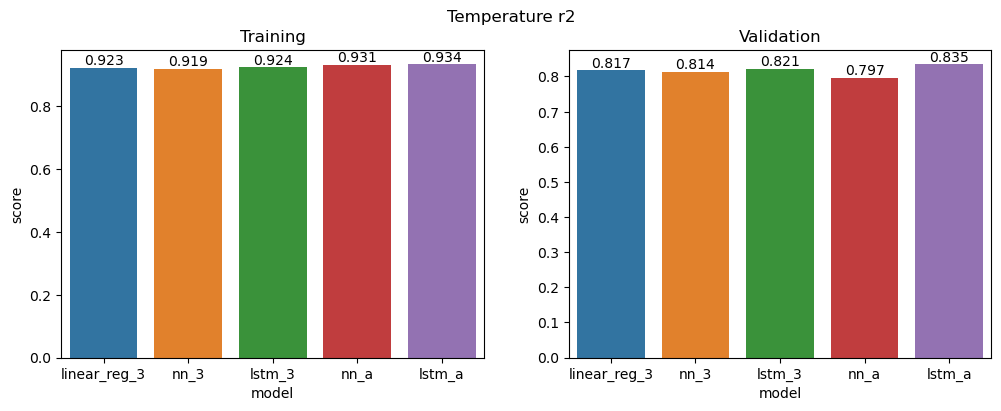

In [102]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

fig.suptitle("Temperature r2")
ax[0].set_title("Training")
ax[1].set_title("Validation")
sns.barplot(data=train_mse, x="model", y="score", hue="model", ax=ax[0])
sns.barplot(data=val_mse, x="model", y="score", hue="model", ax=ax[1])
for n in range(2):
    for container in ax[n].containers:
        ax[n].bar_label(container, fmt='%.3f', padding=0)

# 4. Precipitation

## Feature Engineering

In [103]:
X = ds_uci.to_dataframe()[["msl", "t2m", "u10", "v10"]]
y = (ds_uci["tp"].shift(valid_time=-1) > 0).values

X_train, X_split, y_train, y_split = train_test_split(X, y, random_state=210, shuffle=False, test_size=0.5)

X_val, X_test, y_val, t_test = train_test_split(X_split, y_split, random_state=210, shuffle=False, test_size=0.5)

In [104]:
# Data rescaling

X_scaler = StandardScaler().fit(X_train)

X_train_sc = X_scaler.transform(X_train)
X_val_sc = X_scaler.transform(X_val)
X_test_sc = X_scaler.transform(X_test)

## Logistic Regression

In [105]:
clf = LogisticRegression(max_iter=300, random_state=222)
clf.fit(X_train, y_train)
clf.score(X_val, y_val)

0.6353591160220995

## Neural Network

In [106]:
clf = MLPClassifier(
    hidden_layer_sizes=(16,),
    max_iter=500,
    random_state=222,
    shuffle=False
)
clf.fit(X_val_sc, y_val)

clf.score(X_val_sc, y_val)

0.7513812154696132

In [107]:
class PrecipLSTM(nn.Module):
    def __init__(self, input_dim=4, hidden_dim=32, num_layers=1, output_dim=1):
        super().__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])

In [108]:
MAX_EPOCHS = 300
BATCH_SIZE = 32
PATIENCE = 25
FULL = 1.0  # per-epoch learning-rate multiplier; 1 keeps the full learning rate
CRITERION = nn.BCEWithLogitsLoss()

model, epoch = train_model(
    PrecipLSTM(),
    X_train_sc,
    y_train,
    X_val_sc,
    y_val,
)

with torch.no_grad():
    x = torch.as_tensor(X_val_sc, dtype=torch.float32).unsqueeze(1)
    logits = model(x).numpy().ravel()

rain_prob = 1 / (1 + np.exp(-logits))
lstm_fpr, lstm_tpr, _ = roc_curve(y_val, rain_prob)
lstm_auc = auc(lstm_fpr, lstm_tpr)

NameError: name 'roc_curve' is not defined

## Tree

In [ ]:
from sklearn.tree import DecisionTreeClassifier

clf = DecisionTreeClassifier(random_state=222)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_val)

clf.score(X_val, y_val)

0.580110497237569

## Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

clf = RandomForestClassifier(random_state=222)

clf.fit(X_train, y_train)

y_pred = clf.predict(X_val)

clf.score(X_val, y_val)

0.6187845303867403

## Comparison

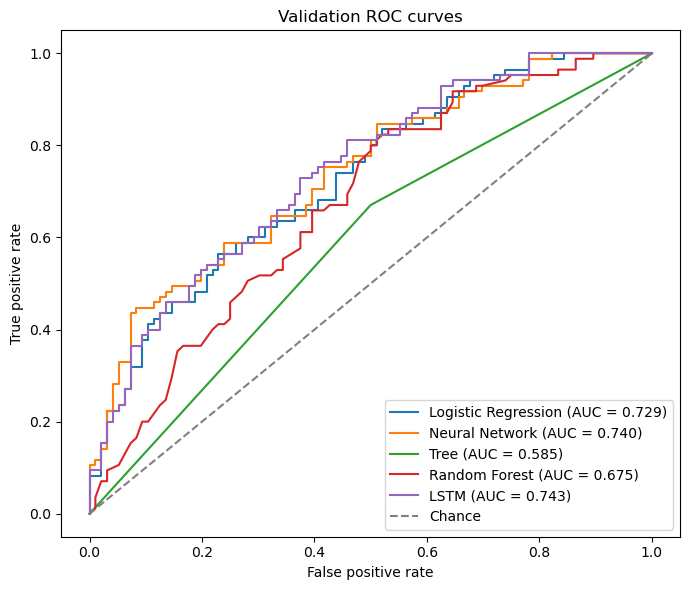

In [ ]:
from sklearn.metrics import auc, roc_curve
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic Regression": (
        LogisticRegression(max_iter=300, random_state=222),
        X_train,
        X_val,
    ),
    "Neural Network": (
        MLPClassifier(
            hidden_layer_sizes=(16,),
            max_iter=500,
            random_state=222,
            shuffle=False,
        ),
        X_train_sc,
        X_val_sc,
    ),
    "Tree": (
        DecisionTreeClassifier(random_state=222),
        X_train,
        X_val,
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=222),
        X_train,
        X_val,
    ),
}

fig, ax = plt.subplots(figsize=(7, 6))
colors = ["tab:blue", "tab:orange", "tab:green", "tab:red"]

for color, (name, (model, X_tr, X_va)) in zip(colors, models.items()):
    model.fit(X_tr, y_train)
    y_score = model.predict_proba(X_va)[:, 1]
    fpr, tpr, _ = roc_curve(y_val, y_score)
    ax.plot(fpr, tpr, color=color, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")
ax.plot(lstm_fpr, lstm_tpr, color="tab:purple", label=f"LSTM (AUC = {lstm_auc:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
ax.set_title("Validation ROC curves")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()